# Tabula Sapiens: IMSTE and UMAP embeddings

Load the prepared PCA features and annotations from `data/tabula_sapiens/cache/`, then fit UMAP and IMSTE once. The same layouts are shown with tissue and cell-type colorings. Prepare the cache first with [the Tabula Sapiens dataset setup notebook](dataset_setup/prepare_tabula_sapiens_dataset.ipynb).


In [1]:
%load_ext autoreload
%autoreload 2

%config InlineBackend.figure_format = 'retina'

from pathlib import Path
import sys
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file()
     and (path / "imste" / "__init__.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate the IMSTE repository from the notebook working directory.")
for local_path in (PROJECT_ROOT, PROJECT_ROOT / "notebooks" / "src"):
    local_path = str(local_path)
    if local_path in sys.path:
        sys.path.remove(local_path)
    sys.path.insert(0, local_path)
import imste
if not Path(imste.__file__).resolve().is_relative_to(PROJECT_ROOT.resolve()):
    raise RuntimeError("This kernel loaded IMSTE from another location; restart and run from the top.")
from imste import IteratedMinimumSpanningTreeEmbedder

DATA_DIR = PROJECT_ROOT / "data" / "tabula_sapiens"
CACHE_DIR = DATA_DIR / "cache"
PREPARED_CACHE = CACHE_DIR / "tabula_sapiens_pca_sample.npz"
PREPARED_MANIFEST = CACHE_DIR / "tabula_sapiens_pca_sample_manifest.json"
if not PREPARED_CACHE.is_file() or not PREPARED_MANIFEST.is_file():
    raise FileNotFoundError(
        "Prepared Tabula Sapiens features are missing. Run "
        "notebooks/dataset_setup/prepare_tabula_sapiens_dataset.ipynb first."
    )
with np.load(PREPARED_CACHE, allow_pickle=False) as saved:
    X = np.asarray(saved["X"], dtype=np.float32)
    tissue_labels = saved["tissue_labels"].astype(str)
    cell_type_labels = saved["cell_type_labels"].astype(str)
manifest = json.loads(PREPARED_MANIFEST.read_text())
if X.ndim != 2 or not np.isfinite(X).all():
    raise ValueError(f"Prepared feature matrix must be finite and 2D; received {X.shape}.")
if len(X) != len(tissue_labels) or len(X) != len(cell_type_labels):
    raise ValueError("Prepared features and annotations have inconsistent row counts.")
if manifest.get("feature_shape") != list(X.shape):
    raise ValueError("Prepared feature matrix shape does not match its manifest.")
RANDOM_STATE = int(manifest["random_state"])
METRIC = "euclidean"
print(f"Loaded {len(X):,} cells × {X.shape[1]} PCs from {PREPARED_CACHE}")
print(f"Tissues: {pd.Series(tissue_labels).nunique():,}; cell types: {pd.Series(cell_type_labels).nunique():,}")
display(pd.DataFrame([manifest]))


Loaded 54,000 cells × 300 PCs from /Users/f.costa/Documents/Projects/Repositories/ACTIVE/IteratedMinimumSpanningTree/data/tabula_sapiens/cache/tabula_sapiens_pca_sample.npz
Tissues: 24; cell types: 54


,dataset,source_file,random_state,sample_by,max_cells_per_class,min_cells_per_cell_type,min_genes_per_cell,min_cells_per_gene,target_sum,n_hvg_requested,...,tissue_column,cell_type_column,n_cells,n_genes,n_tissues,n_cell_types,feature_shape,expression_file,ranked_genes_file,selected_genes_file
0,Tabula Sapiens v1,data/tabula_sapiens/TabulaSapiens.h5ad,42,cell_type,1000,2000,200,3,10000,2000,...,organ_tissue,cell_ontology_class,54000,48285,24,54,"[54000, 300]",data/tabula_sapiens/cache/tabula_sapiens_expre...,data/tabula_sapiens/cache/tabula_sapiens_hvg_r...,data/tabula_sapiens/cache/tabula_sapiens_hvg_s...


## Fit the layouts once

UMAP and the final full-data IMSTE layout are each fitted once. Before the IMSTE fit, a short search tunes settings on a balanced cell-type subset. The plots below reuse the final coordinate arrays for both annotation rows.

## UMAP

Run the next cell by itself to refit and inspect UMAP only. It uses the already prepared `X` and updates `Z_umap`; it does not call the IMSTE estimator. The larger neighborhood and lighter repulsion are intended to reduce the long, sparse arms in the current UMAP view.


In [2]:
# UMAP-only fit: safe to rerun without running IMSTE.
import umap
from scipy.sparse.csgraph import connected_components
from imste.visualization import render_datashader_embedding

UMAP_SETTINGS = {
    "n_components": 2,
    "n_neighbors": 100,
    "min_dist": 0.5,
    "spread": 1.0,
    "repulsion_strength": 0.5,
    "negative_sample_rate": 3,
    "metric": METRIC,
    "init": "random",
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "random_state": RANDOM_STATE,
    "n_epochs": 200,
    "verbose": True,
}

umap_started = time.perf_counter()
umap_model = umap.UMAP(**UMAP_SETTINGS)
Z_umap = umap_model.fit_transform(X)
umap_seconds = time.perf_counter() - umap_started
component_count, component_ids = connected_components(umap_model.graph_, directed=False)
component_sizes = np.bincount(component_ids)
print(
    f"UMAP fit: {umap_seconds:.1f} s; graph components: {component_count}; "
    f"largest sizes: {sorted(component_sizes, reverse=True)[:8]}"
)


UMAP(compatibility_layout=False, init='random', min_dist=0.5, n_epochs=200, n_neighbors=100, nearest_neighbor_backend='rinnd', negative_sample_rate=3, random_state=42, repulsion_strength=0.5, verbose=True)
Fri Nov 20 18:15:22 2026 Construct fuzzy simplicial set
Fri Nov 20 18:15:22 2026 Finding Nearest Neighbors
Fri Nov 20 18:15:22 2026 Using RINND to find nearest neighbors
Building RP forest with 8 trees...
Initializing graph from 3484 leaves...
Running NN-descent for up to 16 iterations...
Iteration 1: 978235 updates
Iteration 2: 80888 updates
Iteration 3: 5155 updates
Converged after 3 iterations

=== Timing Breakdown ===
Forest building:      72.530ms
Leaf initialization: 276.234ms
Candidate building:  102.705ms (3 iters)
Update iterations:  3516.733ms (3 iters)
Total measured:     3968.201ms
Fri Nov 20 18:15:26 2026 Finished Nearest Neighbor Search
Fri Nov 20 18:15:28 2026 Construct embedding
Fri Nov 20 18:15:28 2026 Using adam layout optimizer


Epochs completed:   0%|            0/200 [00:00]

Fri Nov 20 18:15:30 2026 Finished embedding
UMAP fit: 8.3 s; graph components: 1; largest sizes: [np.int64(54000)]


## Fine-tune IMSTE on a cell-type-balanced subset

The search samples up to 50 cells per cell type (2,700 cells for this cache), runs 12 trials at 80 epochs, and scores cell-type predictability plus spatial coverage. Set `IMSTE_SETTINGS["label_strength"]` to zero to use labels only for scoring, or positive to use them in fold-masked tuning fits and the final embedding. The selected settings carry over to the full 54,000-cell fit; `gravity_min_dist` and the final 500-epoch budget remain fixed. Install the optional tuner with `python -m pip install "imste[tuning]"` if needed.

In [3]:
# Keep the full-data budget and gravity spacing floor fixed while tuning the other main controls.
IMSTE_SETTINGS = {
    "n_msts": 128,
    "n_epochs": 500,
    "label_strength": 0.0,  # Set positive for label-aware tuning and fitting.
    "metric": METRIC,
    "random_state": RANDOM_STATE,
    "gravity_strength": 0.1,
    "gravity_min_dist": 5.0,
    "mean_shift_iterations": 1,
}

TUNE_MAX_PER_CELL_TYPE = 50
TUNE_EPOCHS = 80
TUNE_TRIALS = 40
TUNE_SEARCH_SPACE = {
    'n_msts': (2, 64),
    'negative_ratio': (1, 10),
    'logistic_margin': (0.25, 2.0),
    'logistic_temperature': (0.1, 1.0),
    'lambda_rep': (0.25, 0.75),
    'gravity_strength': (0.01, 1.0),
    'gravity_resolution': (0.5, 2.0),
    'gravity_min_dist': (0.01, 1.0),
    'mean_shift_iterations': (1, 5),
    'include_knn_attraction': [False, True],
}

tune_rng = np.random.default_rng(RANDOM_STATE)
tune_indices = []
for cell_type in np.unique(cell_type_labels):
    class_indices = np.flatnonzero(cell_type_labels == cell_type)
    n_selected = min(len(class_indices), TUNE_MAX_PER_CELL_TYPE)
    tune_indices.append(tune_rng.choice(class_indices, size=n_selected, replace=False))
tune_indices = np.sort(np.concatenate(tune_indices))
X_tune = X[tune_indices]
y_tune = cell_type_labels[tune_indices]
print(f"Tuning on {len(tune_indices):,} cells across {len(np.unique(y_tune))} cell types")

tune_mapper = IteratedMinimumSpanningTreeEmbedder(
    n_msts=IMSTE_SETTINGS["n_msts"],
    n_epochs=TUNE_EPOCHS,
    label_strength=IMSTE_SETTINGS["label_strength"],
    random_state=RANDOM_STATE,
    metric=METRIC,
    gravity_strength=IMSTE_SETTINGS["gravity_strength"],
    gravity_min_dist=IMSTE_SETTINGS["gravity_min_dist"],
    mean_shift_iterations=IMSTE_SETTINGS["mean_shift_iterations"],
)
tuning_started = time.perf_counter()
tune_result = tune_mapper.tune(
    X_tune,
    y_tune,
    search_space=TUNE_SEARCH_SPACE,
    n_samples=TUNE_TRIALS,
    n_initial_points=8,
    coverage_weight=0.4,
)
tuning_seconds = time.perf_counter() - tuning_started
IMSTE_SETTINGS.update(tune_result.best_params)

print(f"Best tuning accuracy: {tune_result.best_accuracy:.3f}")
print(f"Best tuning coverage: {tune_result.best_coverage:.3f}")
print("Selected IMSTE settings:", tune_result.best_params)

tuning_trials = pd.DataFrame(tune_result.x_iters, columns=TUNE_SEARCH_SPACE)
tuning_trials["accuracy"] = tune_result.cv_scores
tuning_trials["coverage"] = tune_result.coverage_scores
tuning_trials["objective"] = tune_result.objective_scores
display(tuning_trials.sort_values("objective", ascending=False).reset_index(drop=True))

Tuning on 2,700 cells across 54 cell types
Best tuning accuracy: 0.483
Best tuning coverage: 0.472
Selected IMSTE settings: {'n_msts': np.int64(2), 'negative_ratio': np.int64(8), 'logistic_margin': 0.25, 'logistic_temperature': 0.1, 'lambda_rep': 0.7195308560150228, 'gravity_strength': 0.01, 'gravity_resolution': 1.3573505018950156, 'gravity_min_dist': 0.30945040063588153, 'mean_shift_iterations': np.int64(1), 'include_knn_attraction': np.False_}


,n_msts,negative_ratio,logistic_margin,logistic_temperature,lambda_rep,gravity_strength,gravity_resolution,gravity_min_dist,mean_shift_iterations,include_knn_attraction,accuracy,coverage,objective
0,2,8,0.250000,0.100000,0.719531,0.010000,1.357351,0.309450,1,False,0.482963,0.472386,0.478732
1,2,5,0.763293,0.100000,0.619291,0.010000,0.760812,0.186592,1,False,0.506296,0.400027,0.463789
2,2,4,0.250000,0.100000,0.750000,0.010000,2.000000,0.461263,2,False,0.405556,0.535652,0.457594
3,2,10,0.250000,0.100000,0.476510,1.000000,2.000000,0.080270,1,False,0.635185,0.183840,0.454647
4,2,10,0.429004,0.100000,0.750000,1.000000,1.546837,0.010000,1,False,0.589630,0.239711,0.449662
5,2,7,0.250000,0.100000,0.299407,0.010000,1.376456,0.050944,1,False,0.580370,0.246573,0.446852
6,2,10,0.250000,0.893438,0.750000,0.010000,1.423392,0.250593,1,False,0.547778,0.293304,0.445988
7,2,10,0.617255,0.200484,0.630510,0.864920,1.441346,0.261638,2,False,0.604815,0.190068,0.438916
8,2,9,0.250000,0.130614,0.744360,0.253373,1.689784,0.378539,5,False,0.465556,0.397788,0.438448
9,2,1,0.713630,1.000000,0.250000,0.010000,0.500000,0.010000,1,False,0.627407,0.153938,0.438020


In [4]:
t0 = time.perf_counter()
imste_estimator = IteratedMinimumSpanningTreeEmbedder(**IMSTE_SETTINGS)
Z_imste_refined = imste_estimator.fit_transform(X, y=cell_type_labels)
imste_seconds = time.perf_counter() - t0
imste_fit_seconds = float(imste_estimator.imste_fit_time_)
print(
    f"IMSTE fit: {imste_fit_seconds / 60:.1f} min; "
    f"IMSTE with refinements: {imste_seconds / 60:.1f} min"
)
print(
    f"Gravity spacing floor: adjusted {imste_estimator.gravity_min_dist_pairs_adjusted_:,} "
    f"local pairs to {imste_estimator.gravity_min_dist_used_:.4g} distance units "
    f"({IMSTE_SETTINGS['gravity_min_dist']:.2f} × median starting neighbor spacing)."
)

runtime_rows = [
    ("IMSTE tuning (cell-type subset)", tuning_seconds),
    ("IMSTE FAMST graph construction", imste_estimator.graph_construction_time_),
    ("IMSTE multilevel initialization", imste_estimator.multilevel_initialization_time_),
    ("IMSTE final optimization", imste_estimator.final_embedding_optimization_time_),
    ("IMSTE fit total", imste_fit_seconds),
    ("Gravity refinement", imste_estimator.gravity_time_),
    ("Mean-shift refinement", imste_estimator.mean_shift_time_),
    ("IMSTE total with refinements", imste_seconds),
]
runtime_breakdown = pd.DataFrame(runtime_rows, columns=["stage", "seconds"])
runtime_breakdown["runtime"] = runtime_breakdown["seconds"].map(
    lambda seconds: f"{seconds / 60:.1f} min" if seconds >= 60 else f"{seconds:.1f} s"
)
display(runtime_breakdown)

IMSTE fit: 0.2 min; IMSTE with refinements: 0.3 min
Gravity spacing floor: adjusted 17,924 local pairs to 0.007513 distance units (0.31 × median starting neighbor spacing).


,stage,seconds,runtime
0,IMSTE tuning (cell-type subset),48.848646,48.8 s
1,IMSTE FAMST graph construction,0.867785,0.9 s
2,IMSTE multilevel initialization,0.544468,0.5 s
3,IMSTE final optimization,9.197570,9.2 s
4,IMSTE fit total,10.696992,10.7 s
5,Gravity refinement,5.003488,5.0 s
6,Mean-shift refinement,0.397456,0.4 s
7,IMSTE total with refinements,16.098639,16.1 s


## Compare the same layouts by tissue and cell type

Each row changes only the colors. Columns show UMAP and the final IMSTE layout after gravity and mean shift. No layout is recomputed for the second annotation.

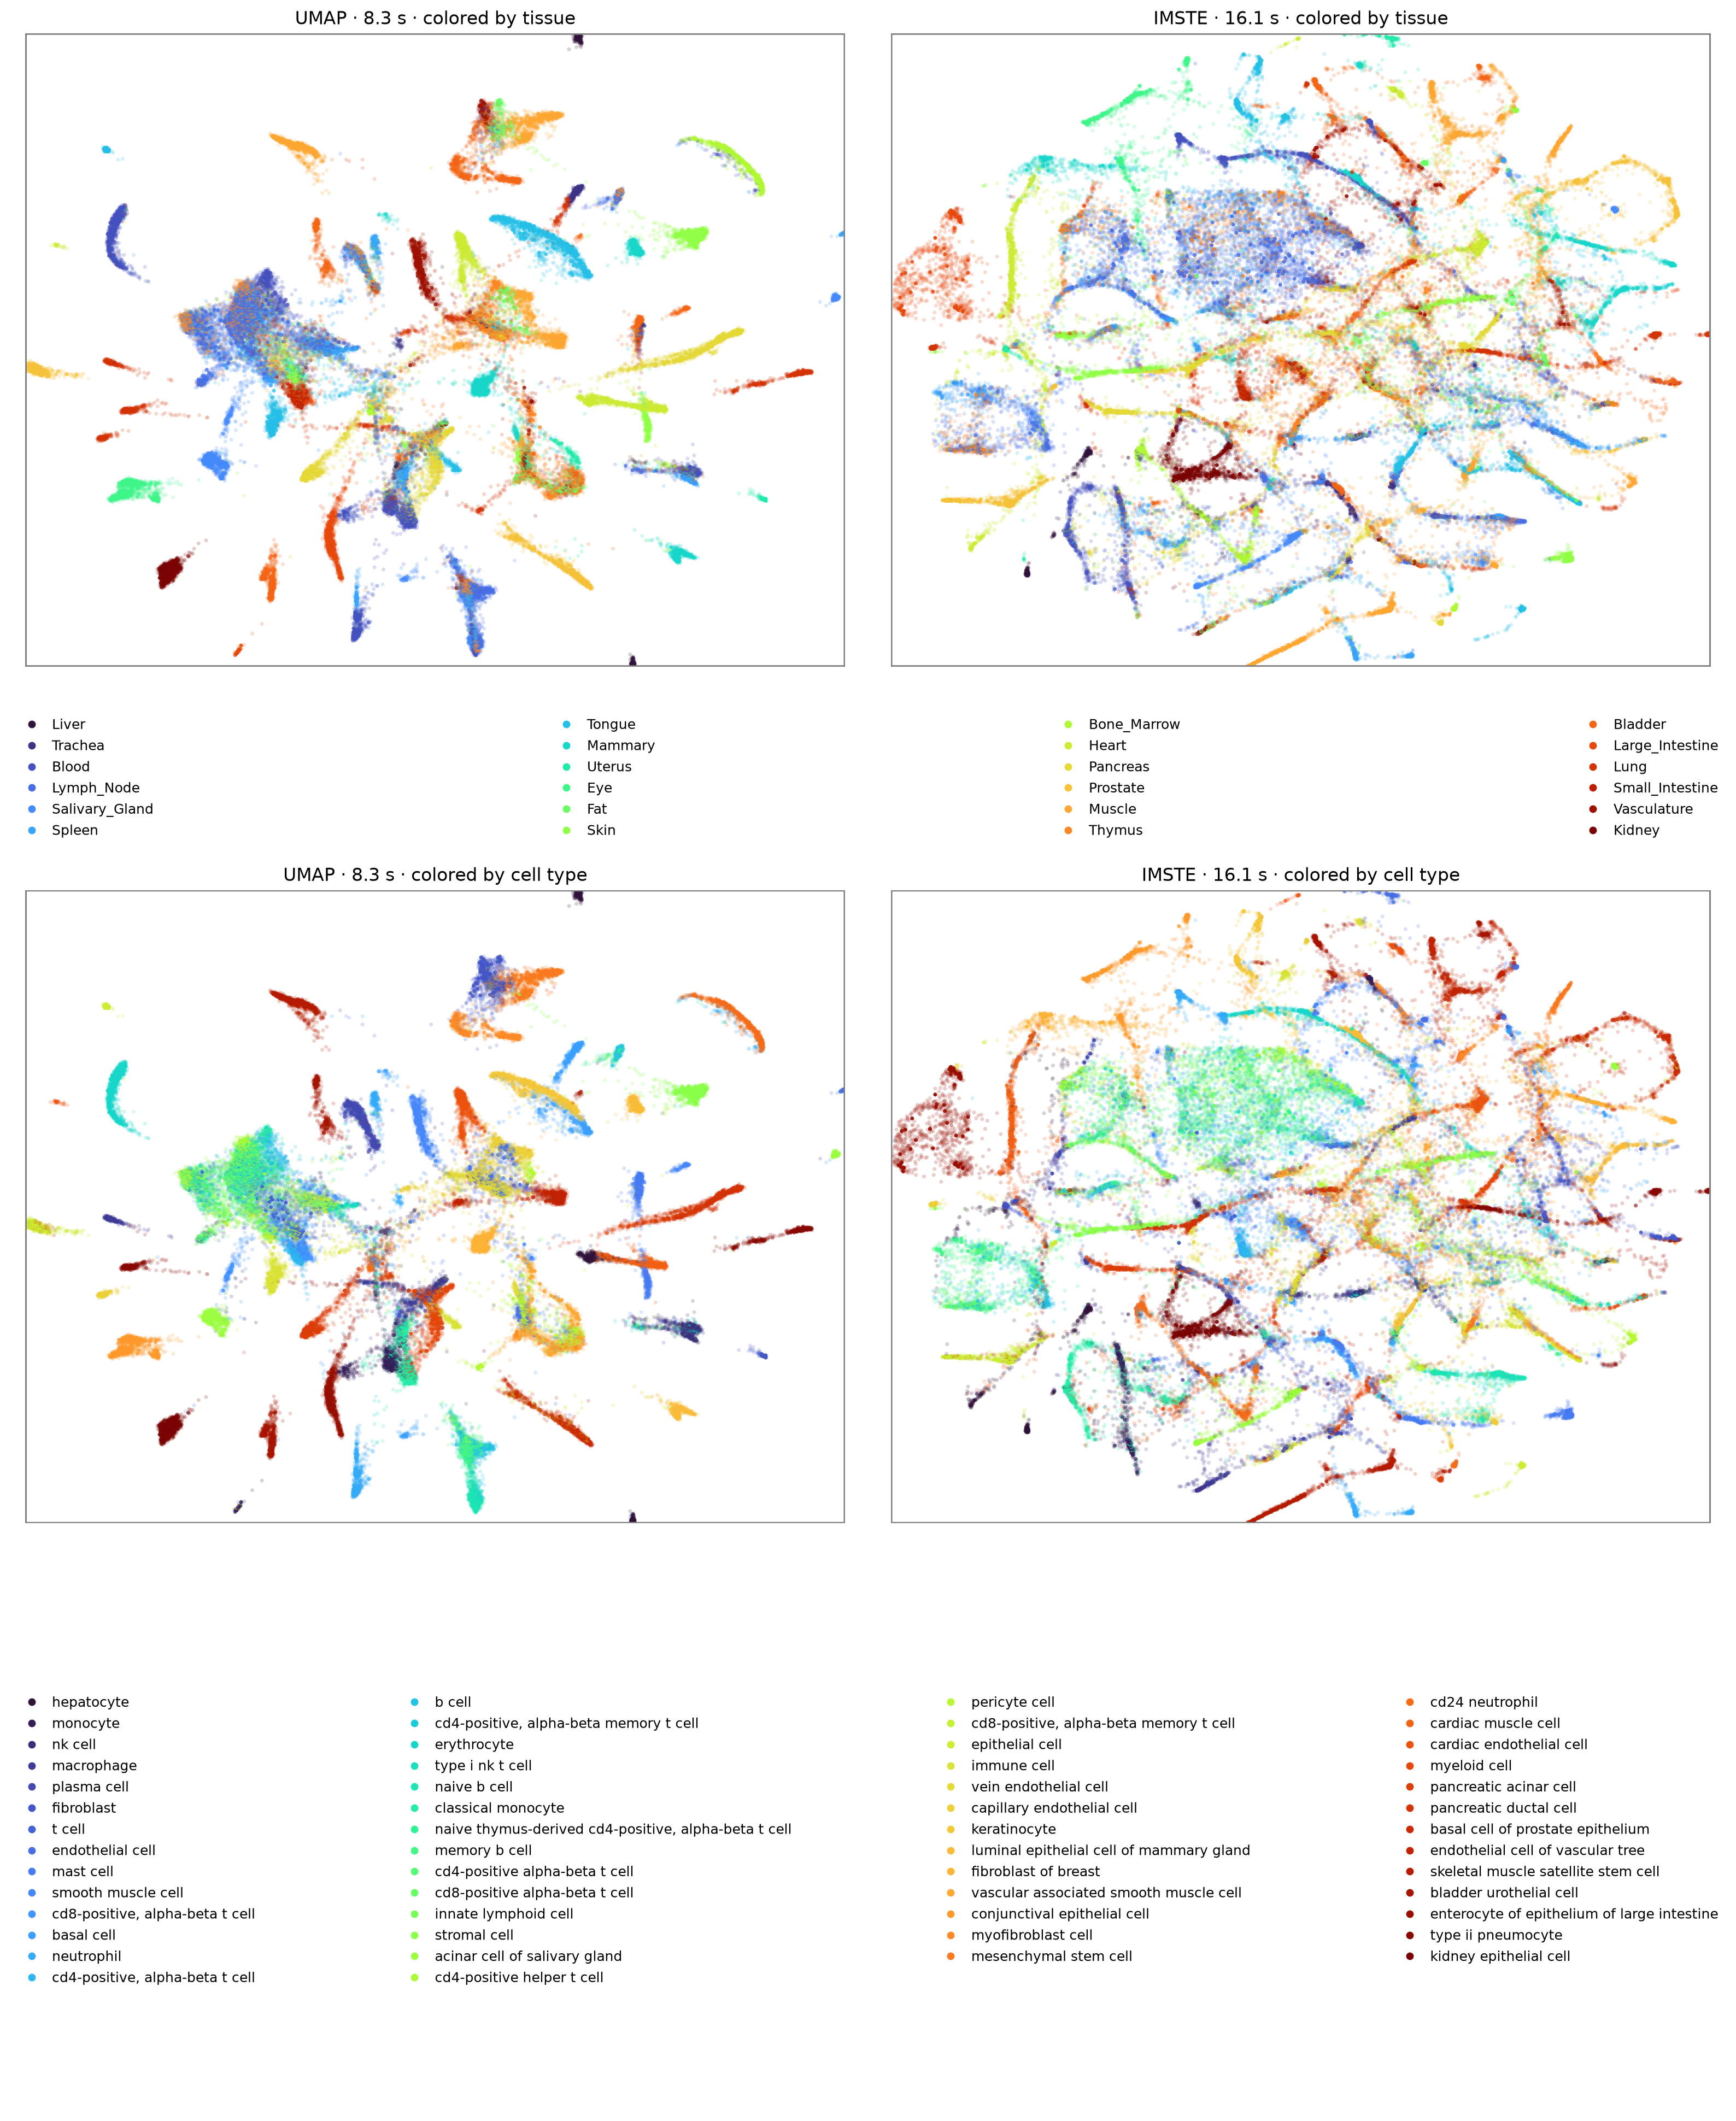

In [5]:
from imste.visualization import render_datashader_embedding
from matplotlib.lines import Line2D

def color_key_for(values):
    categories = list(pd.unique(values))
    cmap = plt.get_cmap("turbo", max(len(categories), 2))
    key = {name: to_hex(cmap(i)) for i, name in enumerate(categories)}
    handles = [
        Line2D([], [], linestyle="None", marker="o", markersize=5,
               markerfacecolor=key[name], markeredgecolor="none", label=name)
        for name in categories
    ]
    return key, handles


def format_runtime(seconds):
    if seconds >= 3600:
        return f"{seconds / 3600:.1f} h"
    if seconds >= 60:
        return f"{seconds / 60:.1f} min"
    return f"{seconds:.1f} s"

layout_specs = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE", Z_imste_refined, imste_seconds),
]
annotation_specs = [
    ("Tissue", tissue_labels, 4),
    ("Cell type", cell_type_labels, 4),
]

fig = plt.figure(figsize=(16, 20), constrained_layout=False)
grid = fig.add_gridspec(
    4, 2,
    height_ratios=(1.0, 0.20, 1.0, 0.85),
    hspace=0.10,
    wspace=0.02,
)
for row, (annotation_name, values, legend_columns) in enumerate(annotation_specs):
    color_key, legend_handles = color_key_for(values)
    plot_row = 0 if row == 0 else 2
    for col, (layout_name, coordinates, seconds) in enumerate(layout_specs):
        ax = fig.add_subplot(grid[plot_row, col])
        image = render_datashader_embedding(
            coordinates[:, :2], values,
            width=1100, height=850,
            color_key=color_key,
            min_alpha=50,
            background="white",
            spread_px=2,
        )
        ax.imshow(image.to_pil())
        ax.set_title(
            f"{layout_name} · {format_runtime(seconds)} · colored by {annotation_name.lower()}"
        )
        ax.set_axis_off()

    legend_ax = fig.add_subplot(grid[plot_row + 1, :])
    legend_ax.set_axis_off()
    legend_ax.legend(
        handles=legend_handles,
        loc="center",
        ncol=legend_columns,
        mode="expand",
        frameon=False,
        fontsize=9,
        columnspacing=1.2,
        handletextpad=0.5,
        labelspacing=0.55,
        borderaxespad=0.1,
    )

fig.subplots_adjust(left=0.01, right=0.99, top=0.97, bottom=0.02)
plt.show()


In [6]:
# Interactive views of the final IMSTE layout (gravity followed by mean shift).
# The two annotation views sit side by side, each with its own legend below.
import ipywidgets as widgets
import plotly.graph_objects as go
from IPython.display import display

SHOW_BLACK_MARKER_EDGE = True  # Set False to hide the thin marker outline.
MARKER_EDGE_WIDTH = 0.35
PLOTLY_FIGURE_WIDTH = 1200
PLOTLY_FIGURE_HEIGHT = max(
    1200,
    22 * max(pd.Series(tissue_labels).nunique(), pd.Series(cell_type_labels).nunique()) + 500,
)

Z_plotly = np.asarray(Z_imste_refined)[:, :2]
if len(Z_plotly) != len(tissue_labels) or len(Z_plotly) != len(cell_type_labels):
    raise ValueError("The refined IMSTE coordinates and annotations must have the same number of cells.")


def plot_imste_by_annotation(coordinates, labels, annotation_name, hover_data):
    categories = list(pd.unique(labels))
    cmap = plt.get_cmap("turbo", max(len(categories), 2))
    label_values = np.asarray(labels)
    fig = go.Figure()

    for color_index, category in enumerate(categories):
        category_mask = label_values == category
        points = coordinates[category_mask]
        category_hover_data = hover_data[category_mask]
        category_color = to_hex(cmap(color_index))
        category_group = f"{annotation_name}:{category}"
        fig.add_trace(go.Scattergl(
            x=points[:, 0], y=points[:, 1],
            customdata=category_hover_data,
            mode="markers",
            name=str(category),
            legendgroup=category_group,
            showlegend=False,
            marker={
                "color": category_color,
                "size": 3,
                "opacity": 0.75,
                "line": {
                    "color": "gray",
                    "width": MARKER_EDGE_WIDTH if SHOW_BLACK_MARKER_EDGE else 0,
                },
            },
            hovertemplate=(
                "Tissue: %{customdata[0]}<br>"
                "Cell type: %{customdata[1]}<extra></extra>"
            ),
        ))
        # A separate square makes each legend entry easy to click.
        fig.add_trace(go.Scatter(
            x=[None], y=[None],
            mode="markers",
            name=str(category),
            legendgroup=category_group,
            marker={"color": category_color, "size": 13, "symbol": "square"},
            hoverinfo="skip",
        ))

    coordinate_min = np.nanmin(coordinates, axis=0)
    coordinate_max = np.nanmax(coordinates, axis=0)
    coordinate_padding = np.maximum((coordinate_max - coordinate_min) * 0.03, 1e-9)
    x_range = [coordinate_min[0] - coordinate_padding[0], coordinate_max[0] + coordinate_padding[0]]
    y_range = [coordinate_min[1] - coordinate_padding[1], coordinate_max[1] + coordinate_padding[1]]
    fig.update_layout(
        template="plotly_white",
        title=f"IMSTE · colored by {annotation_name.lower()}",
        width=PLOTLY_FIGURE_WIDTH,
        height=PLOTLY_FIGURE_HEIGHT,
        margin={"l": 12, "r": 12, "t": 65, "b": 15},
        legend={
            "title": annotation_name, "orientation": "h",
            "x": 0.0, "y": 0.34, "xanchor": "left", "yanchor": "top",
            "entrywidth": 145, "entrywidthmode": "pixels",
            "font": {"size": 10}, "itemclick": "toggle",
            "itemdoubleclick": "toggleothers", "groupclick": "togglegroup",
            "itemsizing": "constant",
        },
        xaxis={"visible": False, "range": x_range, "autorange": False,
               "domain": [0, 1], "constrain": "domain"},
        yaxis={"visible": False, "range": y_range, "autorange": False,
               "domain": [0.38, 1], "scaleanchor": "x", "scaleratio": 1,
               "constrain": "domain"},
        showlegend=True,
    )
    return fig


hover_annotations = np.column_stack((tissue_labels, cell_type_labels))
tissue_plot = plot_imste_by_annotation(Z_plotly, tissue_labels, "Tissue", hover_annotations)
cell_type_plot = plot_imste_by_annotation(Z_plotly, cell_type_labels, "Cell type", hover_annotations)

tissue_output = widgets.Output(layout=widgets.Layout(flex="1 1 0%", min_width="0"))
cell_type_output = widgets.Output(layout=widgets.Layout(flex="1 1 0%", min_width="0"))
with tissue_output:
    display(tissue_plot)
with cell_type_output:
    display(cell_type_plot)

display(widgets.HBox(
    [tissue_output, cell_type_output],
    layout=widgets.Layout(width="100%", align_items="flex-start"),
))
